<a href="https://colab.research.google.com/github/louisbetrisey/2026_Intro_Python/blob/main/FEEDBACK_LOUIS_BETRISEY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Louis Bétrisey Exercise**

I have chosen Exercise 1 from Notebook 1.4 *matplotlib-and-xarray-environmental-exercises*, entitled "NASA’s real global-temperature record". The aim is to plot the annual average temperatures as a curve over time, then to compare this trend with the trend observed month by month. To do this, I have the monthly temperature anomalies produced by NASA from 1880 to 2026, calculated relative to the 1951-1980 average.

**Problem encountered**

The main problem was combining the twelve columns for each month into a single array using the `np.column_stack` function. I copied the exercise’s code exactly as it was, including the `...`: `np.column_stack((data["Jan"], data["Feb"], ..., data["Dec"]))`, without specifying all twelve months. When I ran the cell, I got the following error:
`ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 147 and the array at index 2 has size 1`
The error above surprised me because I didn’t understand where the `size 1` came from. I thought Python would either interpret the ... as "all months" or tell me that this symbol doesn’t exist. Instead, it accepted the code and crashed further on with an error regarding the size of the arrays.


In [2]:
import importlib.util
import subprocess
import sys
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

In [3]:
# Pre-supplied: download the data file and cache it locally.
import pooch

path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/nasa_gistemp_global_temp_anomaly.csv",
    known_hash="sha256:6cfa44e7bbacd9b12cb10bdd64b3182c2735fa3f3a95688e1f7bc8e5dfcece93",
    fname="nasa_gistemp_global_temp_anomaly.csv",
    path=pooch.os_cache("mlees"),
)

In [4]:
data = np.genfromtxt(path, skip_header=1, delimiter=",", names=True,
                    missing_values="***", filling_values=np.nan) # loading the file

In [5]:
np.column_stack((data["Jan"], data["Feb"], ..., data["Dec"])) # error in my code

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 147 and the array at index 2 has size 1

In [6]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"] # creating a list
values = np.column_stack([data[m] for m in months])
print(values.shape)   # (147, 12)

anomaly = xr.DataArray(values, dims=("year", "month"),
                       coords={"year": data["Year"].astype(int), "month": np.arange(1, 13)},
                       attrs={"units": "°C"})

(147, 12)


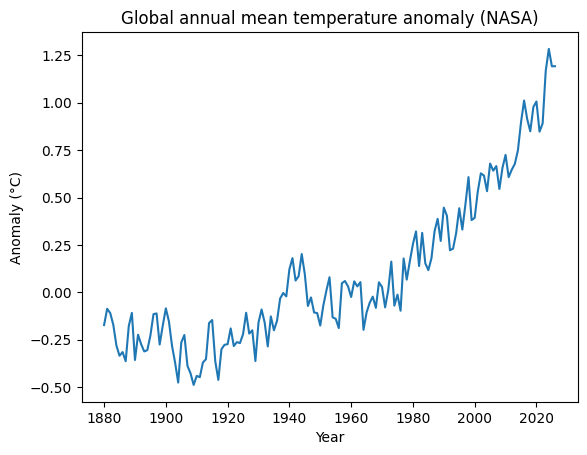

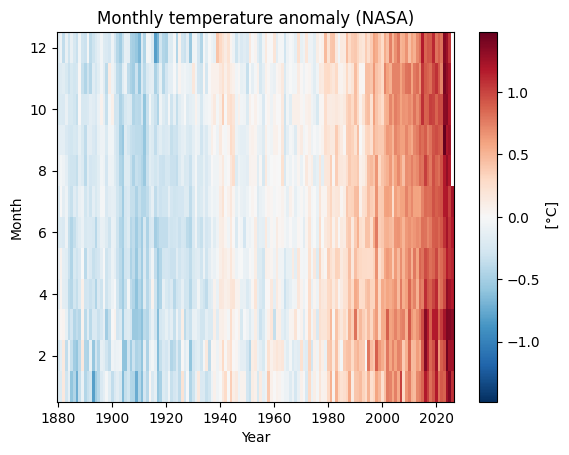

In [7]:
#  Figure 1: annual average (line graph)
annual = anomaly.mean(dim="month")
annual.plot()
plt.title("Global annual mean temperature anomaly (NASA)")
plt.xlabel("Year")
plt.ylabel("Anomaly (°C)")
plt.show()

# Figure 2: all values, year × month (red-blue colour map)
anomaly.plot(x="year")
plt.title("Monthly temperature anomaly (NASA)")
plt.xlabel("Year")
plt.ylabel("Month")
plt.show()

# Comparison: the annual curve shows the general trend, which remained stable until around 1920, followed by a warming trend, particularly since 1980 (more than +1 °C today).
# The month-by-month map shows that every month is getting warmer (blue on the left turns to red on the right), but also the month-to-month variations,
# which the annual average does not reveal. The missing months for 2026 are shown in white.

**Solution and what I learnt**

Whilst investigating the cause of the error, I discovered that in Python, `...` is not a way of saying "and so on, etc.": it is a real object called *Ellipsis* (`print(type(...))` returns `<class “ellipsis”>`).

The error mentioned "size 1" because NumPy treats `...` as a single value, whereas each month column (`data["Jan"]`, `data["Feb"]`, …) contains 147 values, one for each year from 1880 to 2026. `np.column_stack` cannot stack columns of different lengths side by side.

The message referred to "index 2", which corresponds to the third element in my list: after `data["Jan"]` (index 0) and `data["Feb"]` (index 1), it was precisely the `...`. The error message therefore told me exactly where the error was in my code.

So, to fix it, I created a list `months` containing the twelve months from January to December, then used `[data[m] for m in months]` to select all the columns. Next, I checked that the fix worked using `values.shape`, which indeed returned `(147, 12)`.

What I have learnt from this error: next time, I will define my months in advance in a list as I did here, and I will pay attention to the `...` symbol, which can mean something different in Python. I have also learnt that the "index" in an error message helps you quickly identify which element is causing the problem.